In [1]:
%pip install numpy matplotlib seaborn pylatexenc sympy "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Statevector
from qiskit import QuantumCircuit, QuantumRegister

from ApproximateEncoder import ApproximateEncoder
from GroverSearch import GroverSearch
from Visualization import state_analysis
from Loader import save_parameters, load_parameters

In [3]:
num_of_elements = 16
num_of_features = 4

hex_images = [0x0, 0x1, 0x2, 0x3, 0x4, 0x5, 0x6, 0x7, 0x8, 0x9, 0xA, 0xB, 0xC, 0xD, 0xE, 0xF]
dataset = [[(h >> j) & 1 for j in range(num_of_features - 1, -1, -1)] for h in hex_images]

query_index = 11  
query = dataset[query_index]

In [4]:
dataset

[[0, 0, 0, 0],
 [0, 0, 0, 1],
 [0, 0, 1, 0],
 [0, 0, 1, 1],
 [0, 1, 0, 0],
 [0, 1, 0, 1],
 [0, 1, 1, 0],
 [0, 1, 1, 1],
 [1, 0, 0, 0],
 [1, 0, 0, 1],
 [1, 0, 1, 0],
 [1, 0, 1, 1],
 [1, 1, 0, 0],
 [1, 1, 0, 1],
 [1, 1, 1, 0],
 [1, 1, 1, 1]]

In [5]:
query_index

11

In [6]:
query

[1, 0, 1, 1]

# <u>**Part 1: Approximate Encoding Using PQC**</u>

Example for FRQI encoding scheme:

|dataset> = 1/root(N_I*N_D) summation [cosθ|0> + sinθ|1>] |feature no> |index>
            = |q6 q5 q4 q3 q2 q1 q0>
            = |v> |f1 f0> |i3 i2 i1 i0>

In [7]:
encoder = ApproximateEncoder()

## <u>**Encoding with FRQI scheme and MMD cost function**</u>

In [8]:
# A_parameters_frqi_mmd = encoder.generate_encoding(dataset, scheme="FRQI", depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_enocder, learning_rate=learning_rate_dataset_encoder, loss_function_type="MMD")

In [9]:
# B_parameters_frqi_mmd = encoder.generate_encoding(query, scheme="FRQI", depth=pqc_depth_for_query_encoder, epochs=300, learning_rate=0.005, loss_function_type="MMD")

## <u>**Encoding with FRQI scheme and FIDELITY cost function**</u>

Fidelity ignore global phase but captures relative phase.

Example, 

{a|0> + b|1>} and {-a|0>-b|1>} are physically identical

But for (|0>+|1>)/root(2) and (|0>-|1>)/root(2), fidelity is zero (different states)

In [10]:
pqc_depth_for_dataset_encoder = 8
pqc_depth_for_query_encoder = 3
epochs_dataset_encoder = 500
learning_rate_dataset_encoder = 0.05

In [11]:
# Load previously saved A, if available
A_saved_best_fidelity = 0

try:
    A_saved = load_parameters(scheme="FRQI", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]

    print(f"Loaded saved dataset encoder. Fidelity = {A_saved_best_fidelity:.6f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset encoder. Train again.")

Loaded saved dataset encoder. Fidelity = 0.982606



> Preparing dataset target state....

Number of record-index qubits: 4
Number of feature-index qubits: 2
Number of intensity qubits: 1
Total number of qubits: 7
Total number of states: 128

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 96

> Starting training....

Number of parameters = 56

> Using adam optimization....
Epoch 1 - Loss 0.9906046196276997 - Fidelity 0.009395380372300212
Epoch 2 - Loss 0.9735642216648875 - Fidelity 0.026435778335112466
Epoch 3 - Loss 0.9485932591460395 - Fidelity 0.05140674085396049
Epoch 4 - Loss 0.9197712348883162 - Fidelity 0.0802287651116837
Epoch 5 - Loss 0.8886732210289982 - Fidelity 0.11132677897100182
Epoch 6 - Loss 0.8560889962766731 - Fidelity 0.14391100372332694
Epoch 7 - Loss 0.8248311760146463 - Fidelity 0.17516882398535372
Epoch 8 - Loss 0.7960224610587827 - Fidelity 0.2039775389412173
Epoch 9 - Loss 0.7693795321738812 - Fidelity 0.23062046782611875
Epoch 10 - Loss 0.7454659579691905 - Fidelity 0.2545340420308096
Epoch 11 - Loss 0.7236814470268147 - Fidelity 0.2763185529731853
Epoch 12 - Loss 0.7018684322088646 - Fidelity 0.2981315677911354
Epoch 13 - Loss 0.6788746301686868 - Fidelity 0.3211253698313132
Epoch 14 - Loss 0.6554019280892

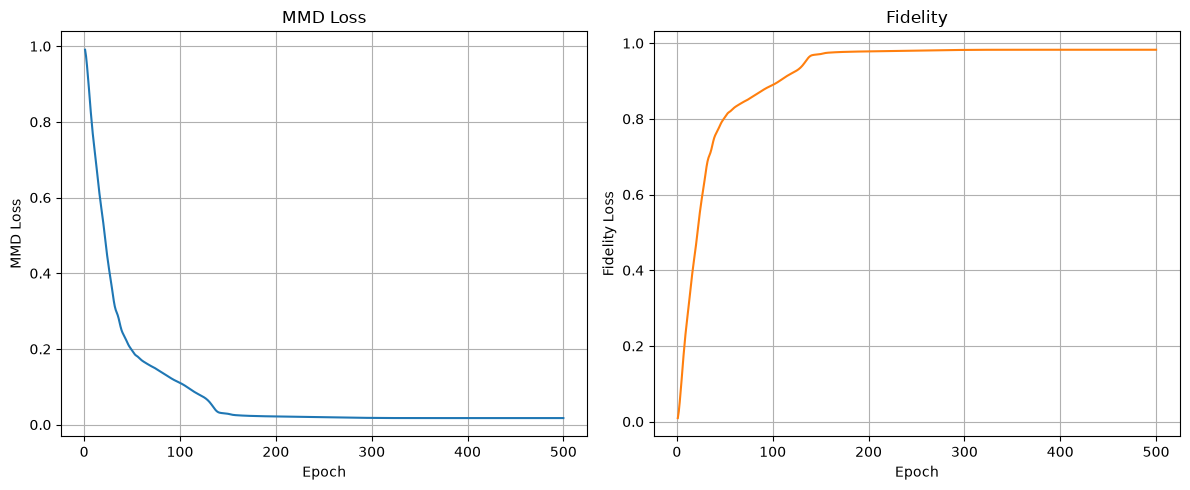


> Training finished.
Number of qubits: 7
Circuit depth (layers): 8
Number of parameters: 56
Best fidelity achieved: 0.98260610


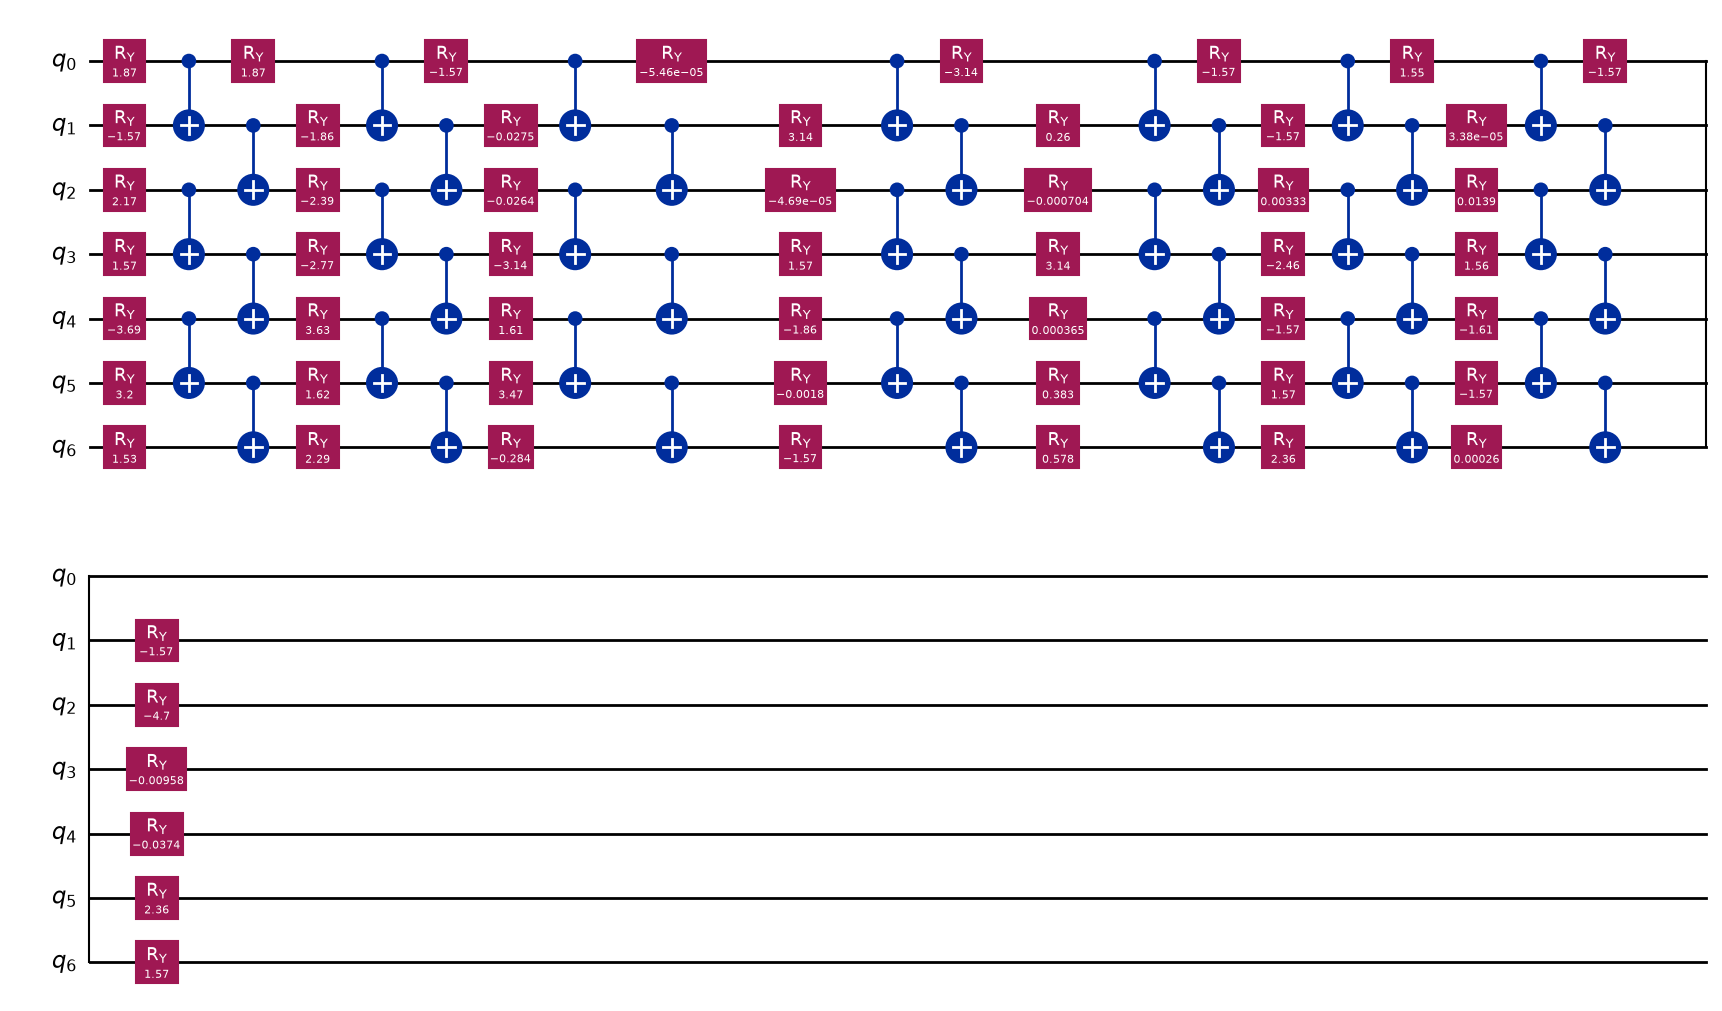


Data =  [[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.98260610


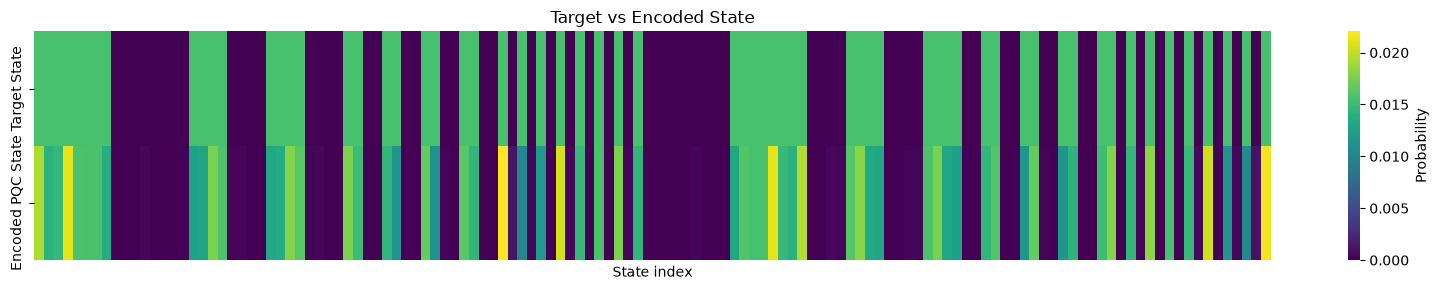

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

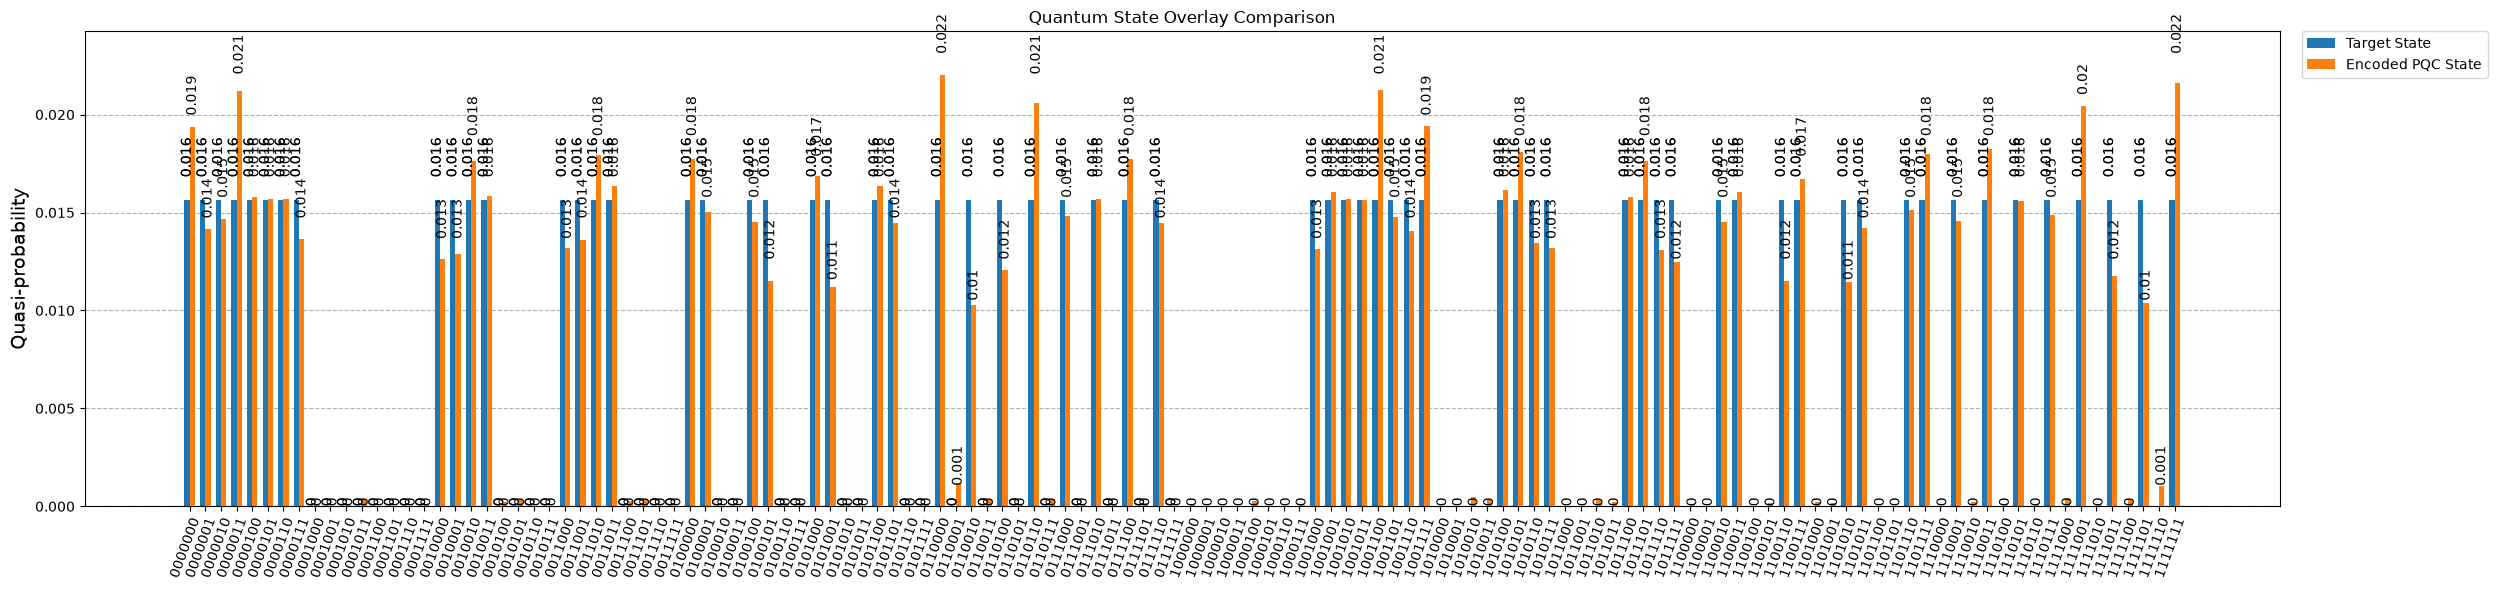


TARGET STATE
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.125                   +0.000                   
0                        1                        +0.125                   +0.000                   
0                        2                        +0.125                   +0.000                   
0                        3                        +0.125                   +0.000                   
1                        0                        +0.125                   +0.000                   
1                        1                        +0.125                   +0.000                   
1                        2                        +0.125                   +0.000                   
1                        3                        +0.000                   +0

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.1391155488989058+0j)
|0000001> : (0.11892832405656305+0j)
|0000010> : (0.12111400615995181+0j)
|0000011> : (0.1456644760669747+0j)
|0000100> : (0.1256733303758106+0j)
|0000101> : (0.12531996997914316+0j)
|0000110> : (0.12528042474979703+0j)
|0000111> : (0.11685130257741738+0j)
|0001000> : (0.009047875350194556+0j)
|0001001> : (-0.005394998643934502+0j)
|0001010> : (-0.006833646195350595+0j)
|0001011> : (0.019610729588981243+0j)
|0001100> : (-0.003153675223215583+0j)
|0001101> : (0.005208454163439881+0j)
|0001110> : (0.0023304993846426066+0j)
|0001111> : (-0.009439786985429938+0j)
|0010000> : (0.11247730083958482+0j)
|0010001> : (0.11344015576717159+0j)
|0010010> : (0.13274014948001936+0j)
|0010011> : (0.12589641982089722+0j)
|0010100> : (0.014298651537041752+0j)
|0010101> : (0.01826187335005797+0j)
|0010110> : (-0.0004062393291535686+0j)
|0010111> : (0.0020118423837647316+0j)
|0011000> : (0.11480747962862631+0j)
|0011001> : (0.11651371987328

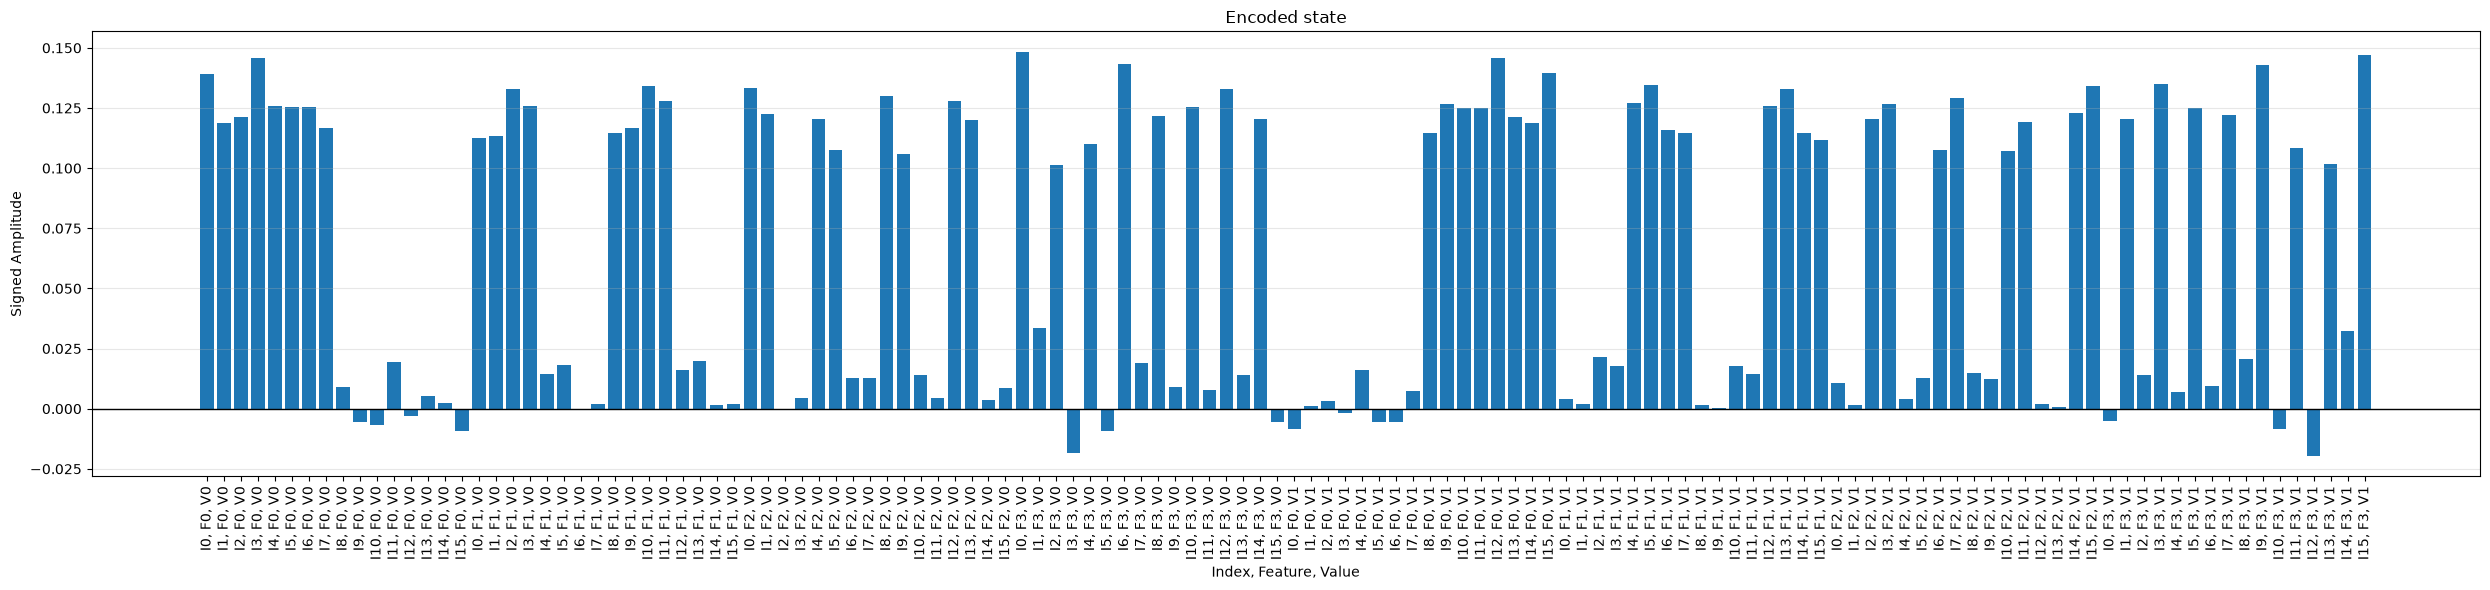


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


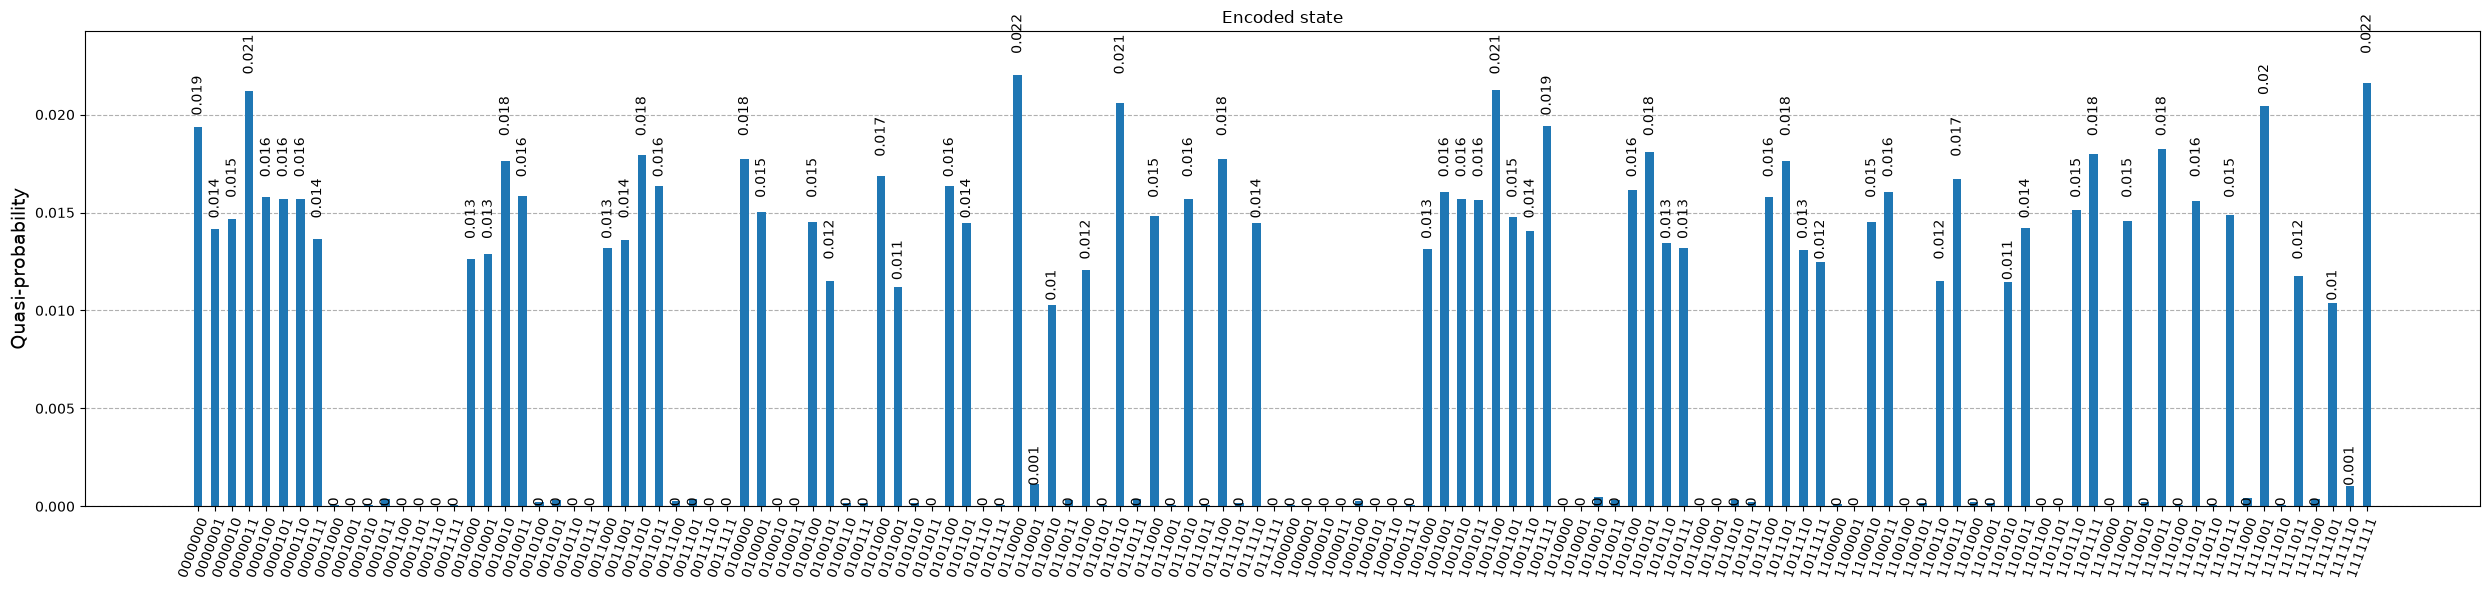

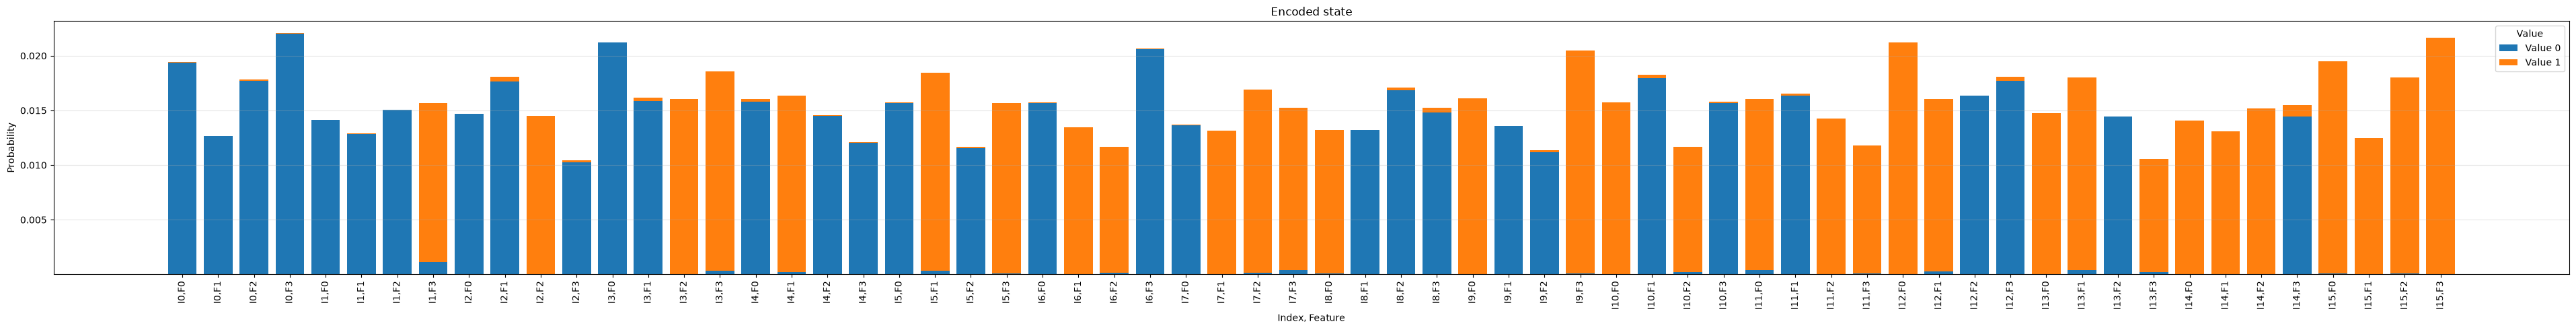


Encoded state
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.139                   -0.008                   
0                        1                        +0.112                   +0.004                   
0                        2                        +0.133                   +0.011                   
0                        3                        +0.148                   -0.005                   
1                        0                        +0.119                   +0.001                   
1                        1                        +0.113                   +0.002                   
1                        2                        +0.123                   +0.002                   
1                        3                        +0.033                   +

In [12]:
A_parameters, A_best_fidelity = encoder.generate_encoding(dataset, scheme="FRQI", depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, learning_rate=learning_rate_dataset_encoder, loss_function_type="FIDELITY")

In [ ]:
if A_best_fidelity > A_saved_best_fidelity:
    save_parameters(
        A_parameters,
        depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, 
        learning_rate=learning_rate_dataset_encoder, fidelity=A_best_fidelity,
        scheme="FRQI", loss_function_type="FIDELITY"
    )

    print("New dataset encoder has better fidelity. Saved the new parameters.")

else:
    print(f"New dataset encoder did not improve fidelity {A_saved_best_fidelity}. Keeping the previous best parameters.")

print(f"Final best dataset encoder fidelity = {A_best_fidelity:.6f}")

New dataset encoder did not improve fidelity 0.9826061048081526. Keeping the previous best parameters.
Final best A fidelity = 0.982606



> Preparing query target state....

Number of feature-index qubits: 2
Number of intensity qubits: 1
Total number of qubits: 3
Total number of states: 8

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 7

> Starting training....

Number of parameters = 9

> Using adam optimization....
Epoch 1 - Loss 0.7536694199031233 - Fidelity 0.24633058009687672
Epoch 2 - Loss 0.6932617651335324 - Fidelity 0.3067382348664676
Epoch 3 - Loss 0.6475102697531234 - Fidelity 0.35248973024687663
Epoch 4 - Loss 0.6141819313074973 - Fidelity 0.3858180686925027
Epoch 5 - Loss 0.5849797508113556 - Fidelity 0.41502024918864444
Epoch 6 - Loss 0.547528900322604 - Fidelity 0.4524710996773959
Epoch 7 - Loss 0.4931303655314633 - Fidelity 0.5068696344685367
Epoch 8 - Loss 0.4227954041206019 - Fidelity 0.5772045958793981
Epoch 9 - Loss 0.34312885906835255 - Fidelity 0.6568711409316474
Epoch 10 - Loss 0.2627841478706394 - Fidelity 0.7372158521293606
Epoch 11 - Loss 0.18975026621871216 - Fidelity 0.8102497337812878
Epoch 12 - Loss 0.13036172488829656 - Fidelity 0.8696382751117034
Epoch 13 - Loss 0.0885455553884813 - Fidelity 0.9114544446115187
Epoch 14 - Loss 0.06504857924290575 -

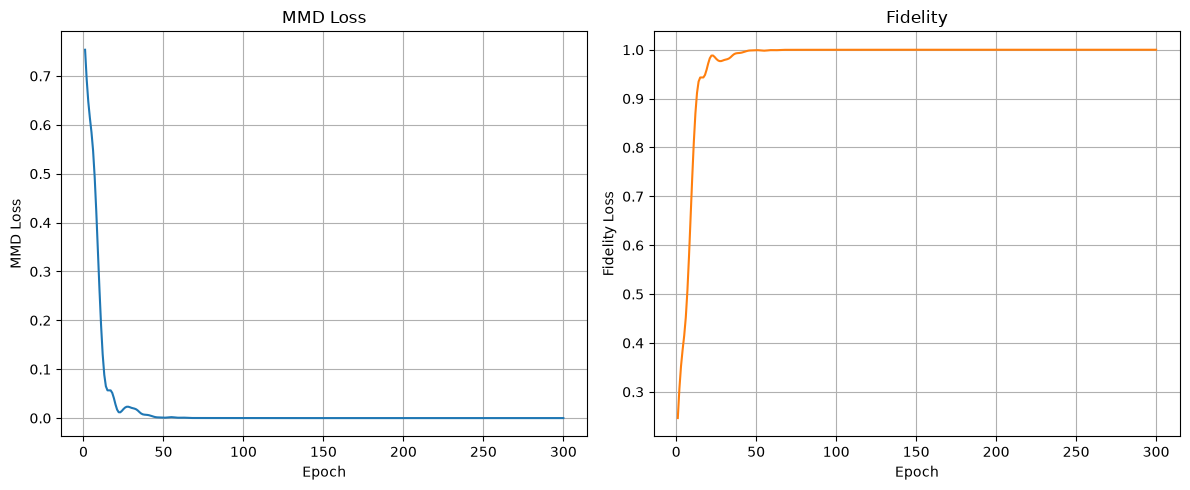


> Training finished.
Number of qubits: 3
Circuit depth (layers): 3
Number of parameters: 9
Best fidelity achieved: 0.99999951


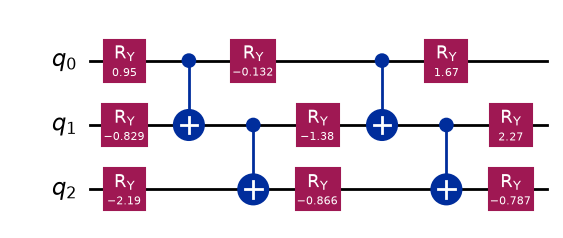


Data =  [1 0 1 1]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99999951


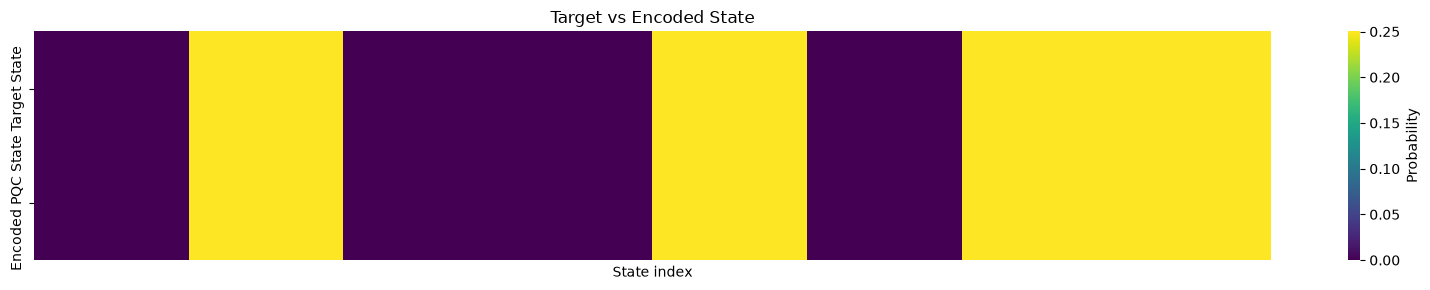

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

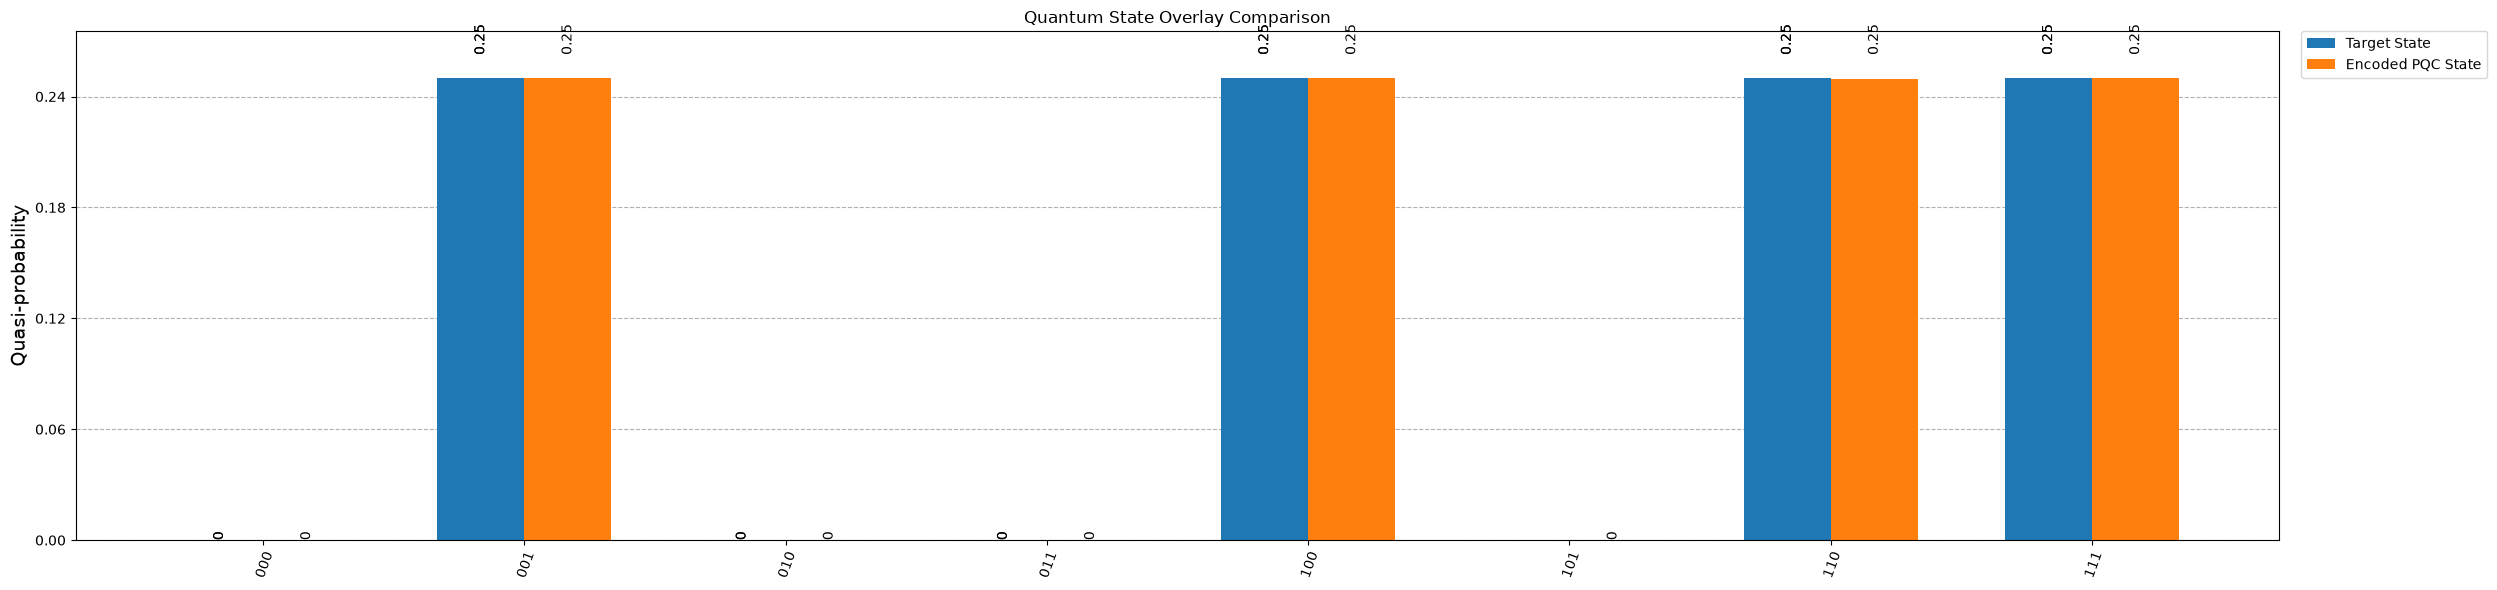


TARGET STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.000                   +0.500                   
1                        +0.500                   +0.000                   
2                        +0.000                   +0.500                   
3                        +0.000                   +0.500                   

ENCODED STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        -0.000                   -0.500                   
1                        -0.500                   +0.000                   
2                        +0.000                   -0.500                   
3                        -0.000                   -0.500                   

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000> : (-0.0002764483434014616+0j)
|001> : (-0.4999379777405613+0j)
|010> : (4.2226192678330395e-05+0j)
|011> : (-0.0003546586618858453+0j)
|100> : (-0.50024382572398+0j)
|110> : (-0.49958826990328753+0j)
|111> : (-0.5002294371767798+0j)


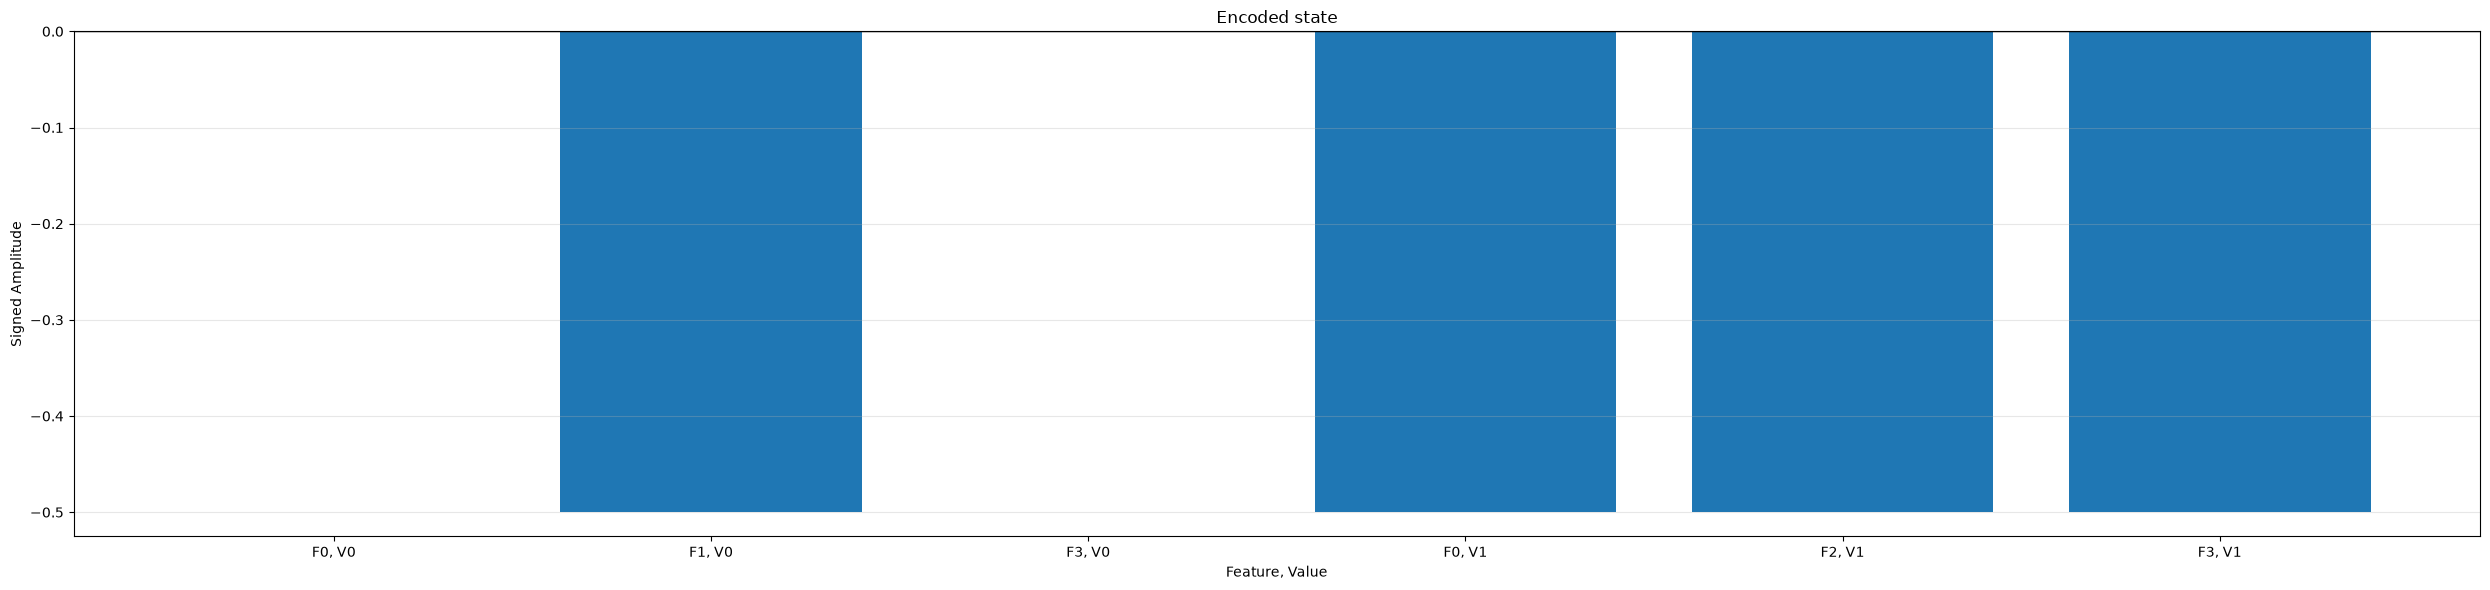


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


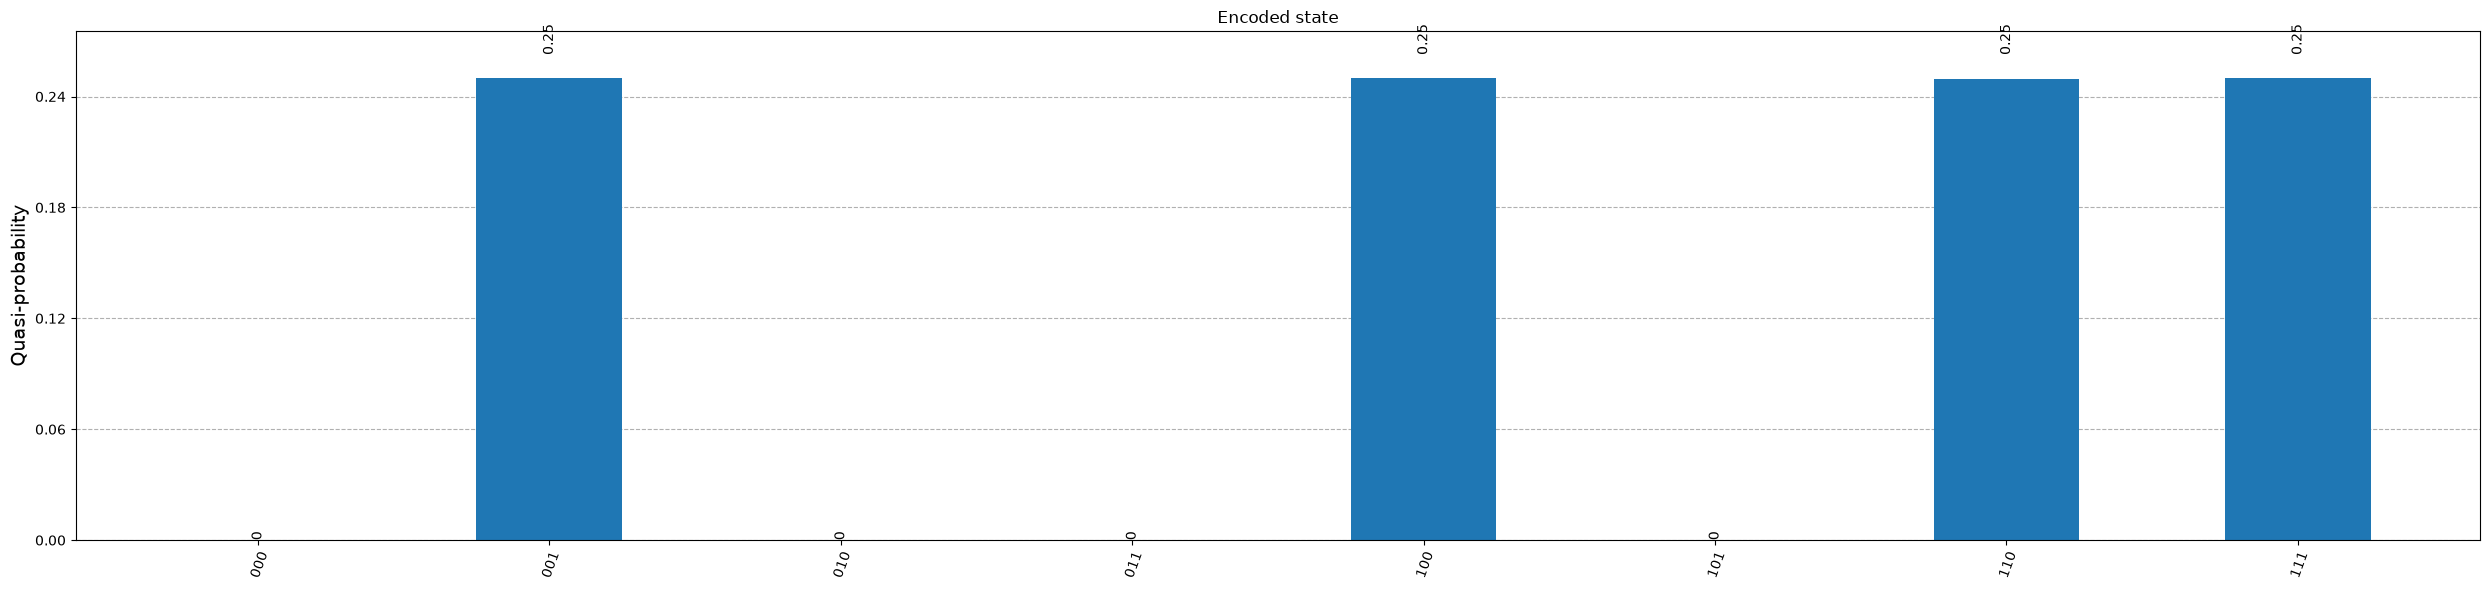

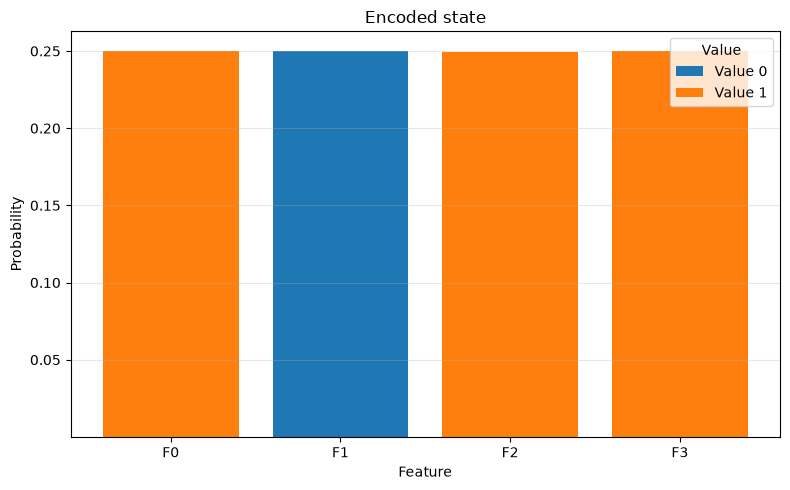


Encoded state
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        -0.000                   -0.500                   
1                        -0.500                   +0.000                   
2                        +0.000                   -0.500                   
3                        -0.000                   -0.500                   


In [14]:
B_parameters_frqi_fidelity, _ = encoder.generate_encoding(query, scheme="FRQI", depth=pqc_depth_for_query_encoder, epochs=300, learning_rate=0.1, loss_function_type="FIDELITY")

## <u>**U operation**</u>

U = (B† ⊗ I_I) A

In [15]:
n_index_q = math.ceil(math.log2(len(dataset)))
n_feature_q = math.ceil(math.log2(len(dataset[0])))

max_value = int(np.max(dataset))
n_value_q = max(1, math.ceil(math.log2(max_value + 1)))
print("Index qubits = ", n_index_q)
print("Feature qubits = ", n_feature_q)
print("Value qubits = ", n_value_q)

Index qubits =  4
Feature qubits =  2
Value qubits =  1


In [16]:
A = encoder.pqc(
    A_parameters, depth=pqc_depth_for_dataset_encoder, n_qubits=(n_index_q + n_feature_q + n_value_q)
)

In [17]:
B = encoder.pqc(
    B_parameters_frqi_fidelity, depth=pqc_depth_for_query_encoder, n_qubits=(n_value_q + n_feature_q)
)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (1+0j)


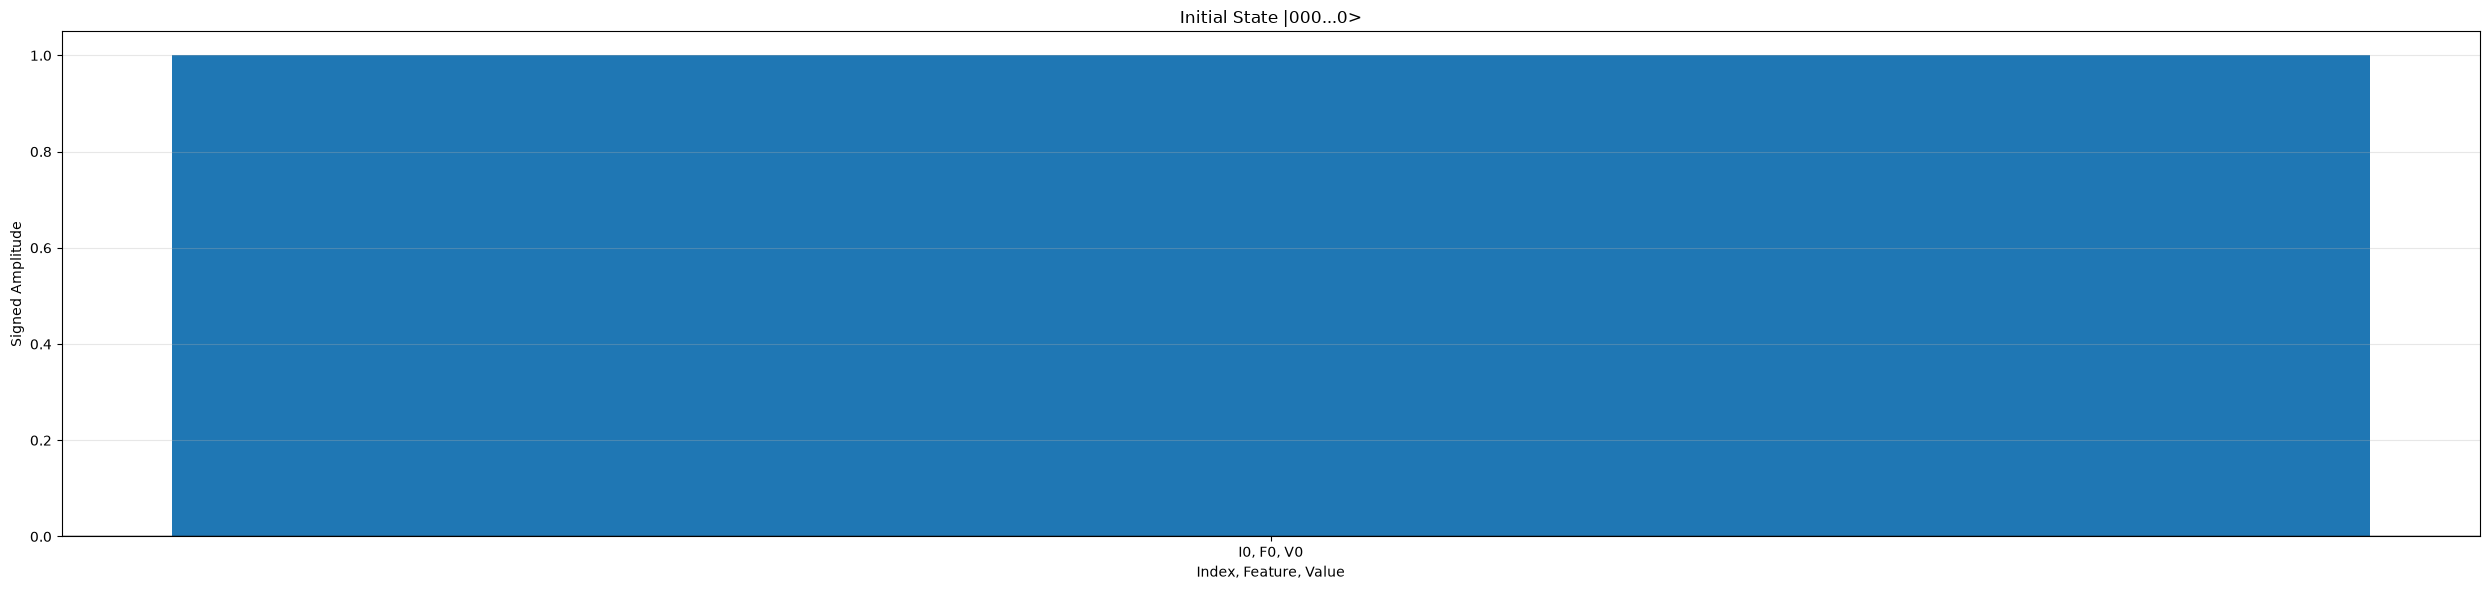


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


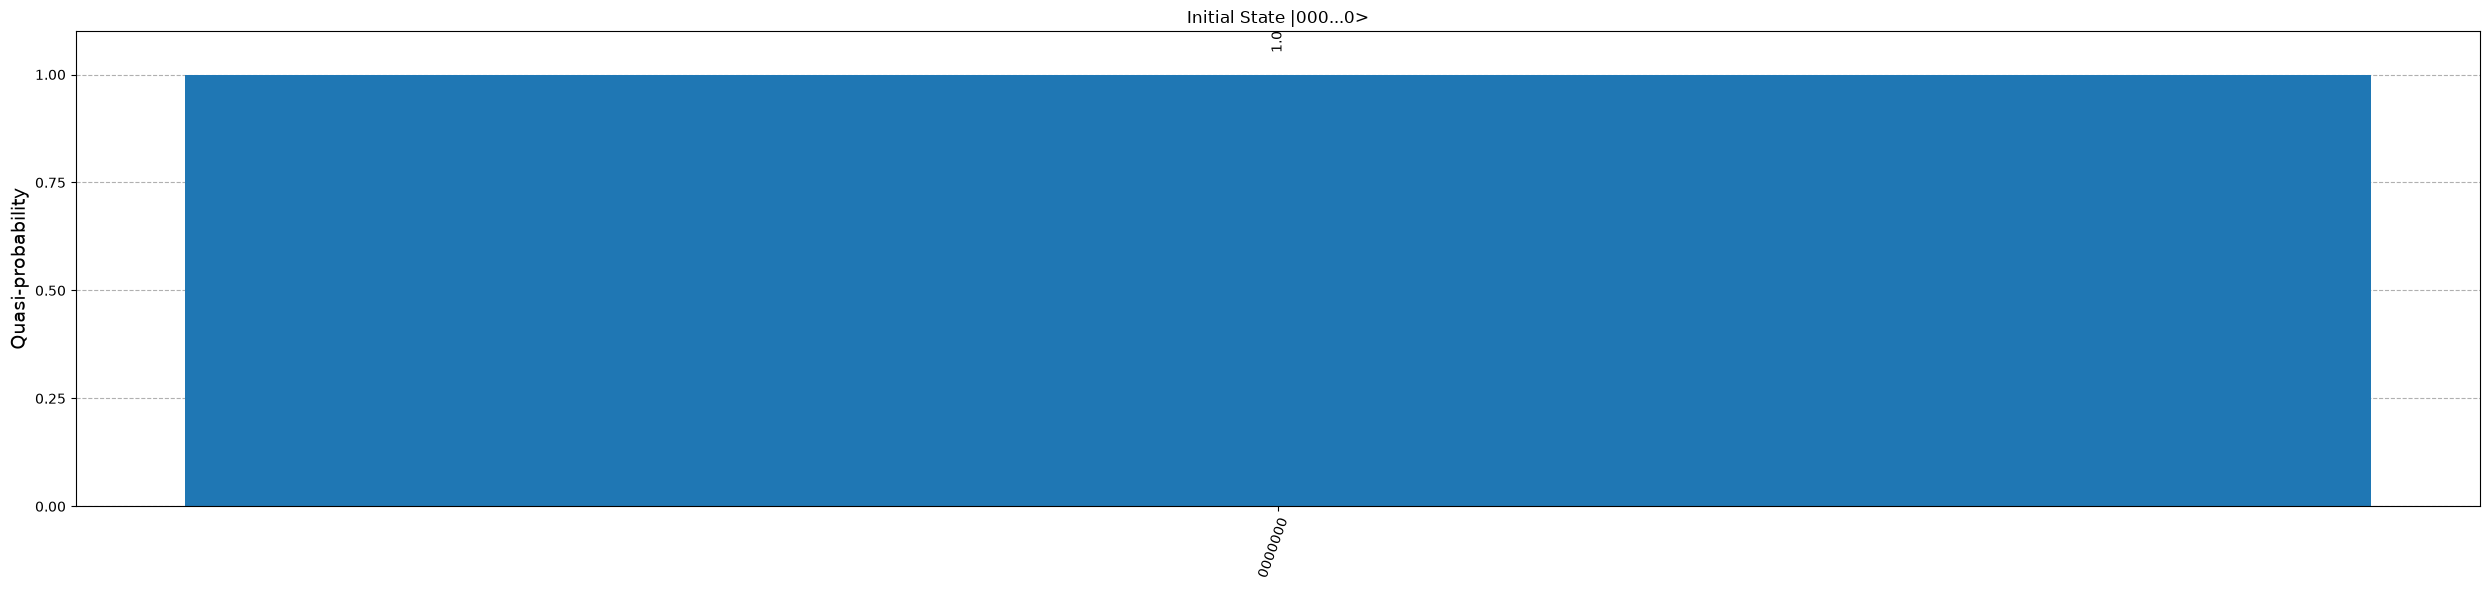

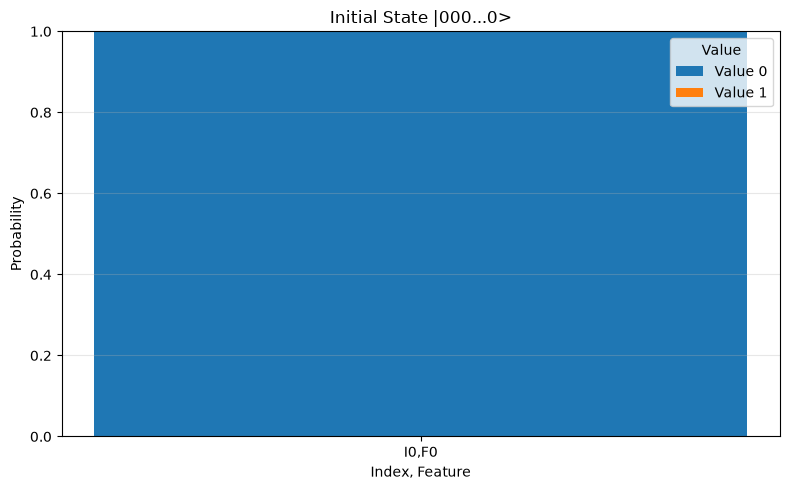


Initial State |000...0>
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +1.000                   +0.000                   


In [18]:
value_reg = QuantumRegister(n_value_q)
feature_reg = QuantumRegister(n_feature_q)
index_reg = QuantumRegister(n_index_q)
qc = QuantumCircuit(value_reg, feature_reg, index_reg)

initial_state = Statevector.from_instruction(qc)
state_analysis(initial_state, "Initial State |000...0>", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.1391155488989058+0j)
|0000001> : (0.11892832405656305+0j)
|0000010> : (0.12111400615995181+0j)
|0000011> : (0.1456644760669747+0j)
|0000100> : (0.1256733303758106+0j)
|0000101> : (0.12531996997914316+0j)
|0000110> : (0.12528042474979703+0j)
|0000111> : (0.11685130257741738+0j)
|0001000> : (0.009047875350194556+0j)
|0001001> : (-0.005394998643934502+0j)
|0001010> : (-0.006833646195350595+0j)
|0001011> : (0.019610729588981243+0j)
|0001100> : (-0.003153675223215583+0j)
|0001101> : (0.005208454163439881+0j)
|0001110> : (0.0023304993846426066+0j)
|0001111> : (-0.009439786985429938+0j)
|0010000> : (0.11247730083958482+0j)
|0010001> : (0.11344015576717159+0j)
|0010010> : (0.13274014948001936+0j)
|0010011> : (0.12589641982089722+0j)
|0010100> : (0.014298651537041752+0j)
|0010101> : (0.01826187335005797+0j)
|0010110> : (-0.0004062393291535686+0j)
|0010111> : (0.0020118423837647316+0j)
|0011000> : (0.11480747962862631+0j)
|0011001> : (0.11651371987328

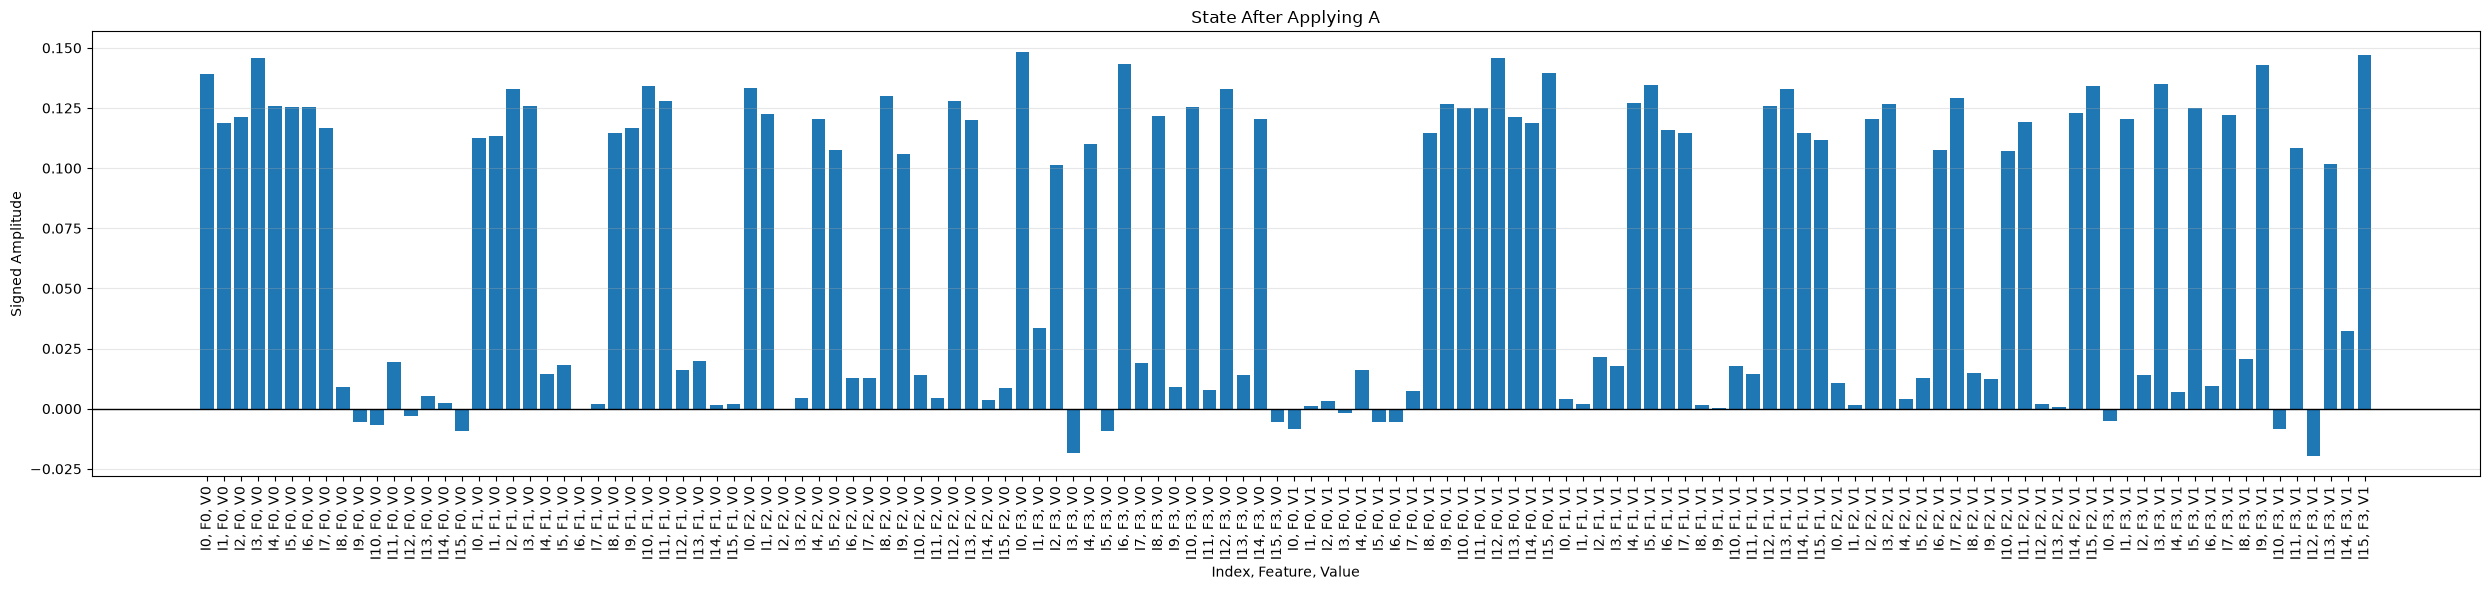


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


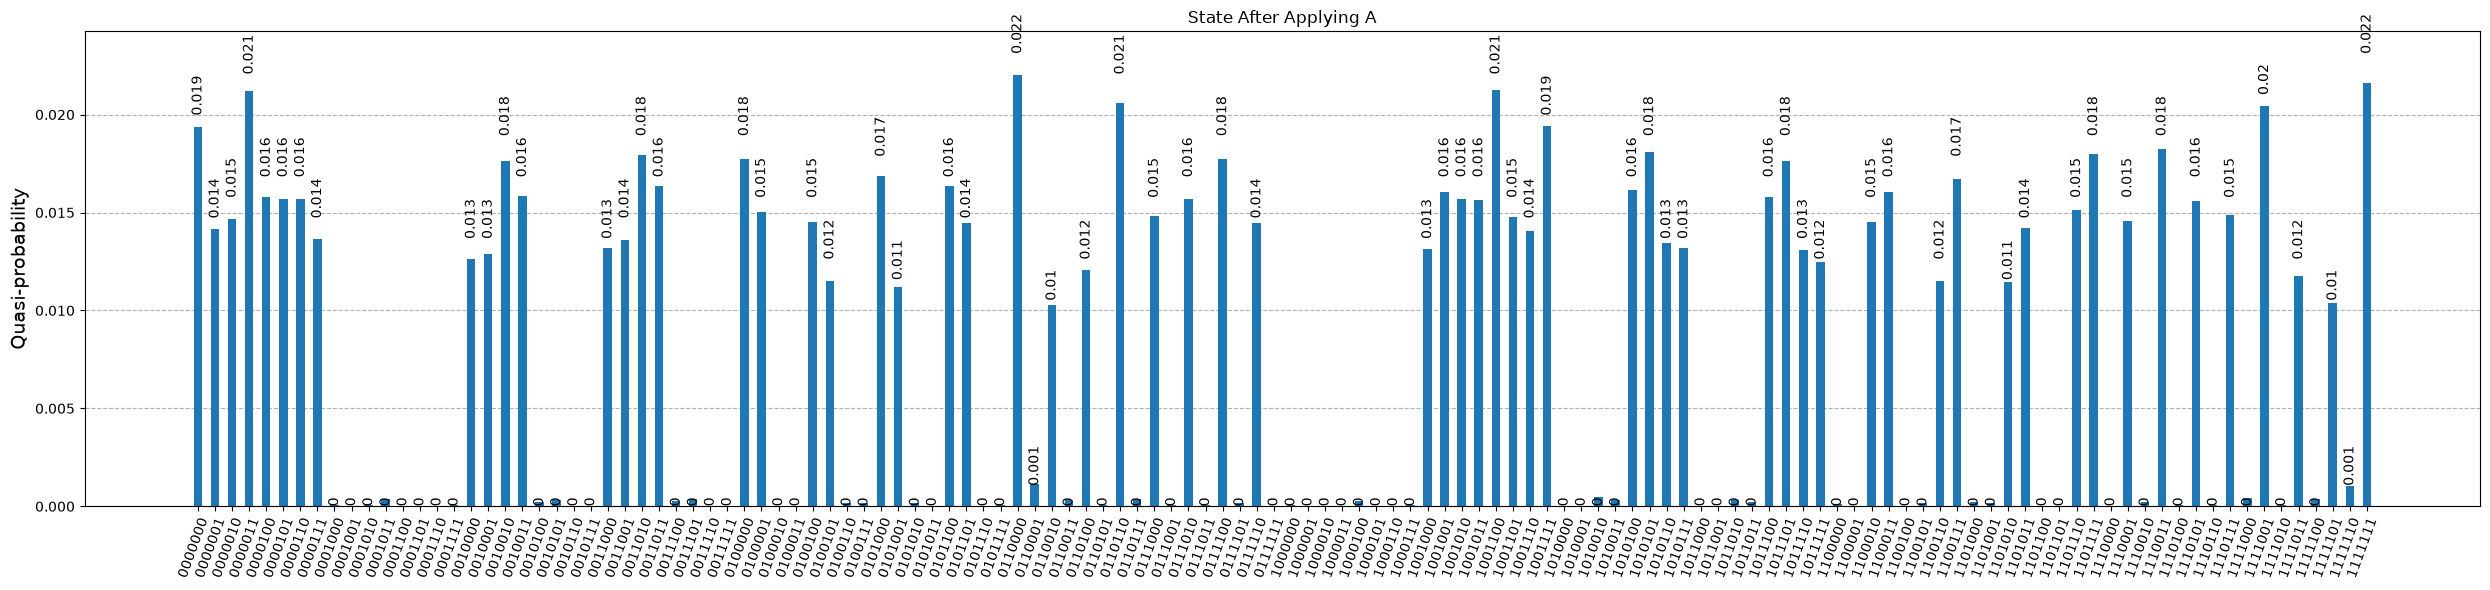

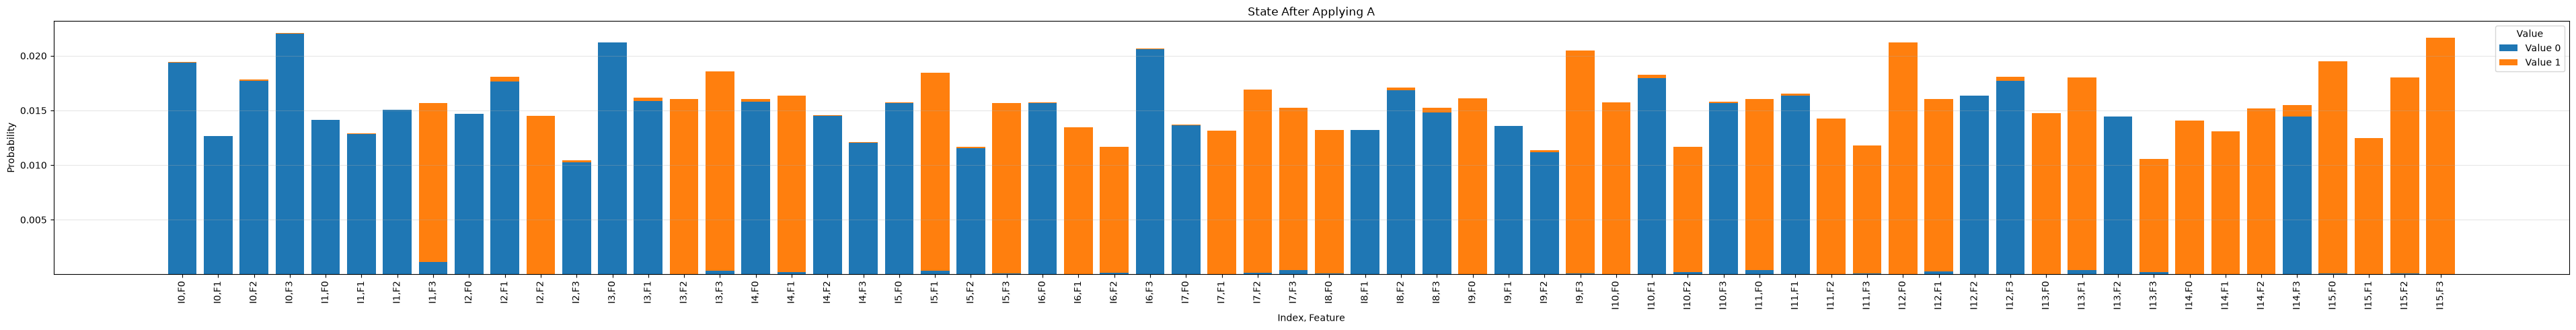


State After Applying A
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.139                   -0.008                   
0                        1                        +0.112                   +0.004                   
0                        2                        +0.133                   +0.011                   
0                        3                        +0.148                   -0.005                   
1                        0                        +0.119                   +0.001                   
1                        1                        +0.113                   +0.002                   
1                        2                        +0.123                   +0.002                   
1                        3                        +0.033           

In [19]:
qc.compose(A, inplace=True)
qc.barrier()

state_after_A = Statevector.from_instruction(qc)

state_analysis(state_after_A, "State After Applying A", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.24344990893984947+0j)
|0000001> : (0.1480750286876684+0j)
|0000010> : (-0.006271978563113586+0j)
|0000011> : (-0.040284190233497504+0j)
|0000100> : (0.12350663670144242+0j)
|0000101> : (-0.056284010541857+0j)
|0000110> : (0.16089447927713227+0j)
|0000111> : (-0.05538120865237986+0j)
|0001000> : (0.007822807209044925+0j)
|0001001> : (0.00679773530664226+0j)
|0001010> : (-0.004947669281183338+0j)
|0001011> : (-0.010872203652383608+0j)
|0001100> : (0.014736504472945722+0j)
|0001101> : (0.01167776031856035+0j)
|0001110> : (0.006706745937671883+0j)
|0001111> : (-0.005025844131992396+0j)
|0010000> : (-0.06473938285629878+0j)
|0010001> : (0.040115769586729084+0j)
|0010010> : (-0.07678155059926599+0j)
|0010011> : (0.030856033951700727+0j)
|0010100> : (0.11953646100645475+0j)
|0010101> : (-0.07639999632885534+0j)
|0010110> : (0.15291430798881483+0j)
|0010111> : (-0.05809607046983533+0j)
|0011000> : (-0.0680087673633648+0j)
|0011001> : (0.04136485660

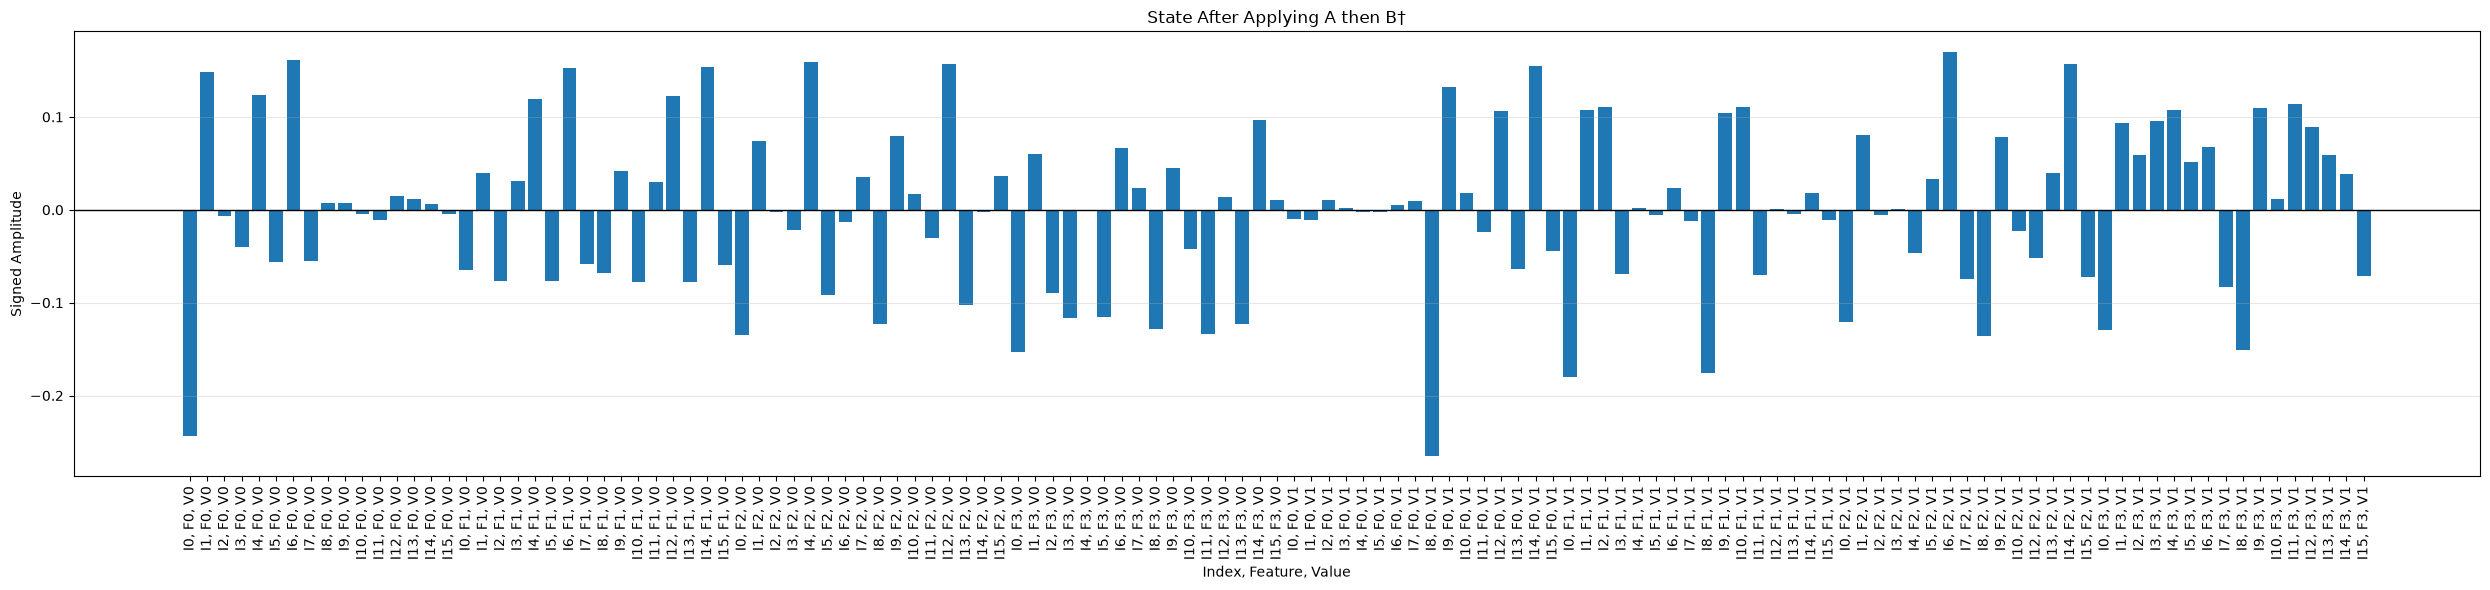


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


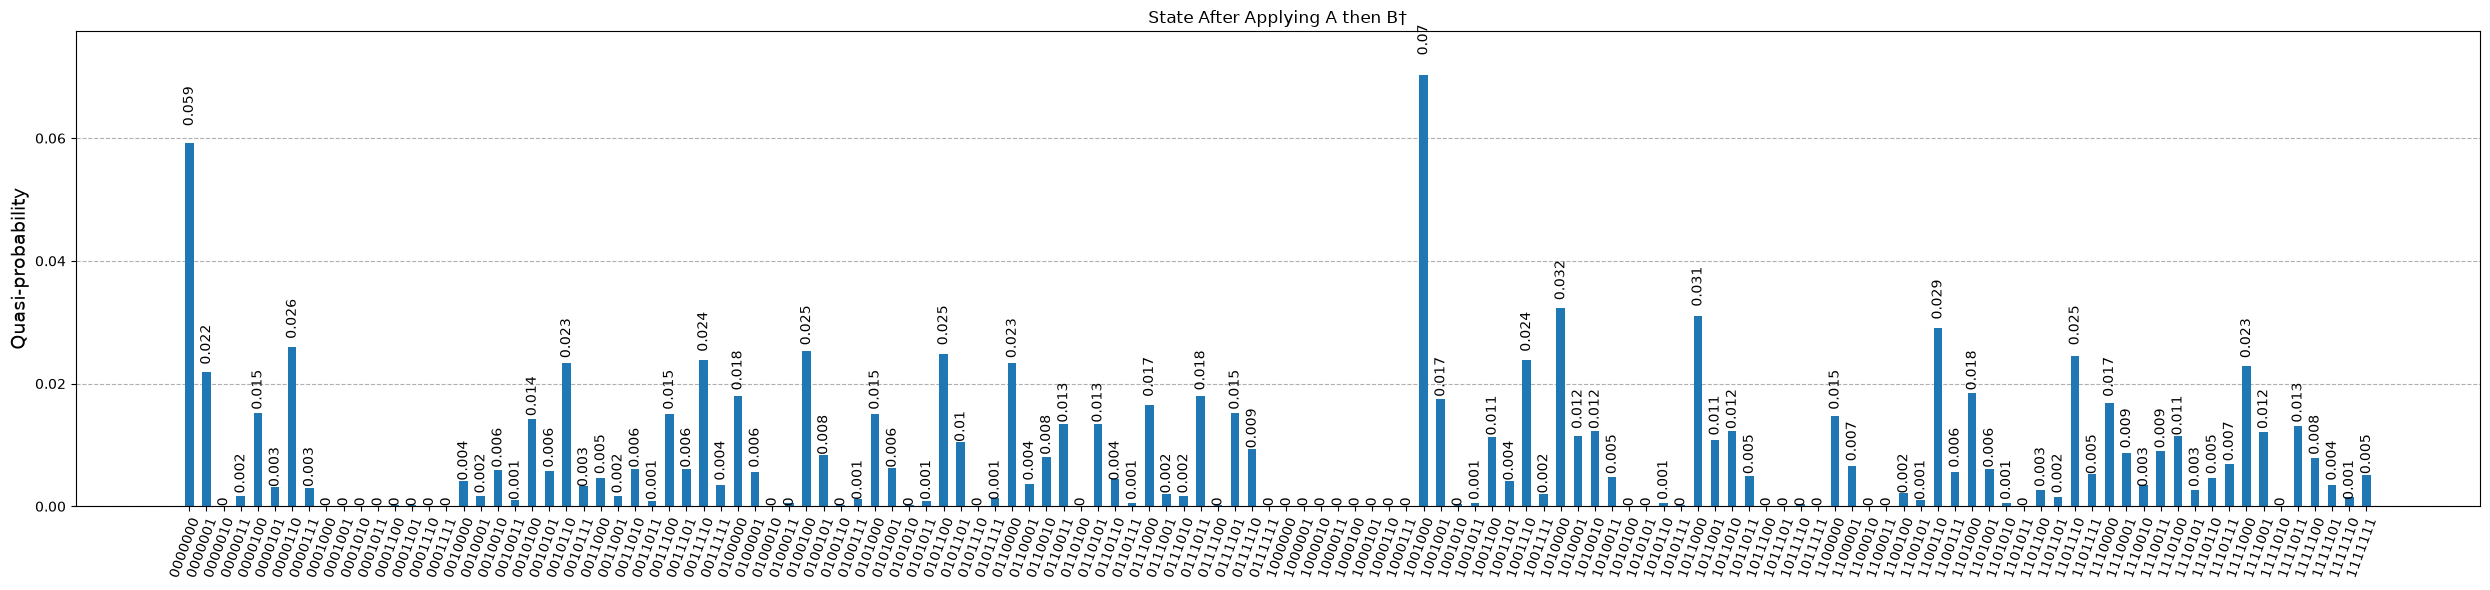

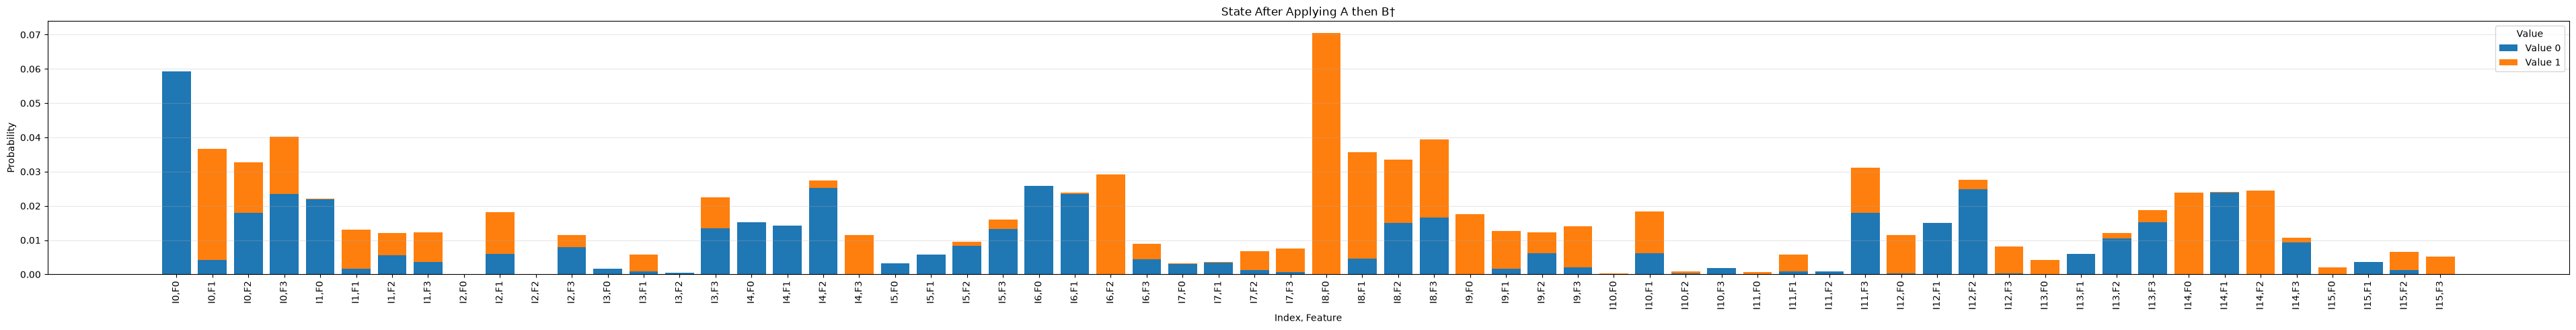


State After Applying A then B†
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.243                   -0.010                   
0                        1                        -0.065                   -0.180                   
0                        2                        -0.134                   -0.121                   
0                        3                        -0.153                   -0.129                   
1                        0                        +0.148                   -0.012                   
1                        1                        +0.040                   +0.107                   
1                        2                        +0.075                   +0.081                   
1                        3                        +0.060   

In [20]:
qc.compose(B.inverse(), qubits=range(n_feature_q + n_value_q), inplace=True)
qc.barrier()

state_after_B_inverse = Statevector.from_instruction(qc)

state_analysis(state_after_B_inverse, "State After Applying A then B†", n_value_q, n_feature_q, n_index_q)

For query index = 0
Total probability for index 0 =  (-0.250)^2+(+0.000)^2+(-0.249)^2+(-0.000)^2+(-0.125)^2+(-0.126)^2+(-0.124)^2+(-0.126)^2

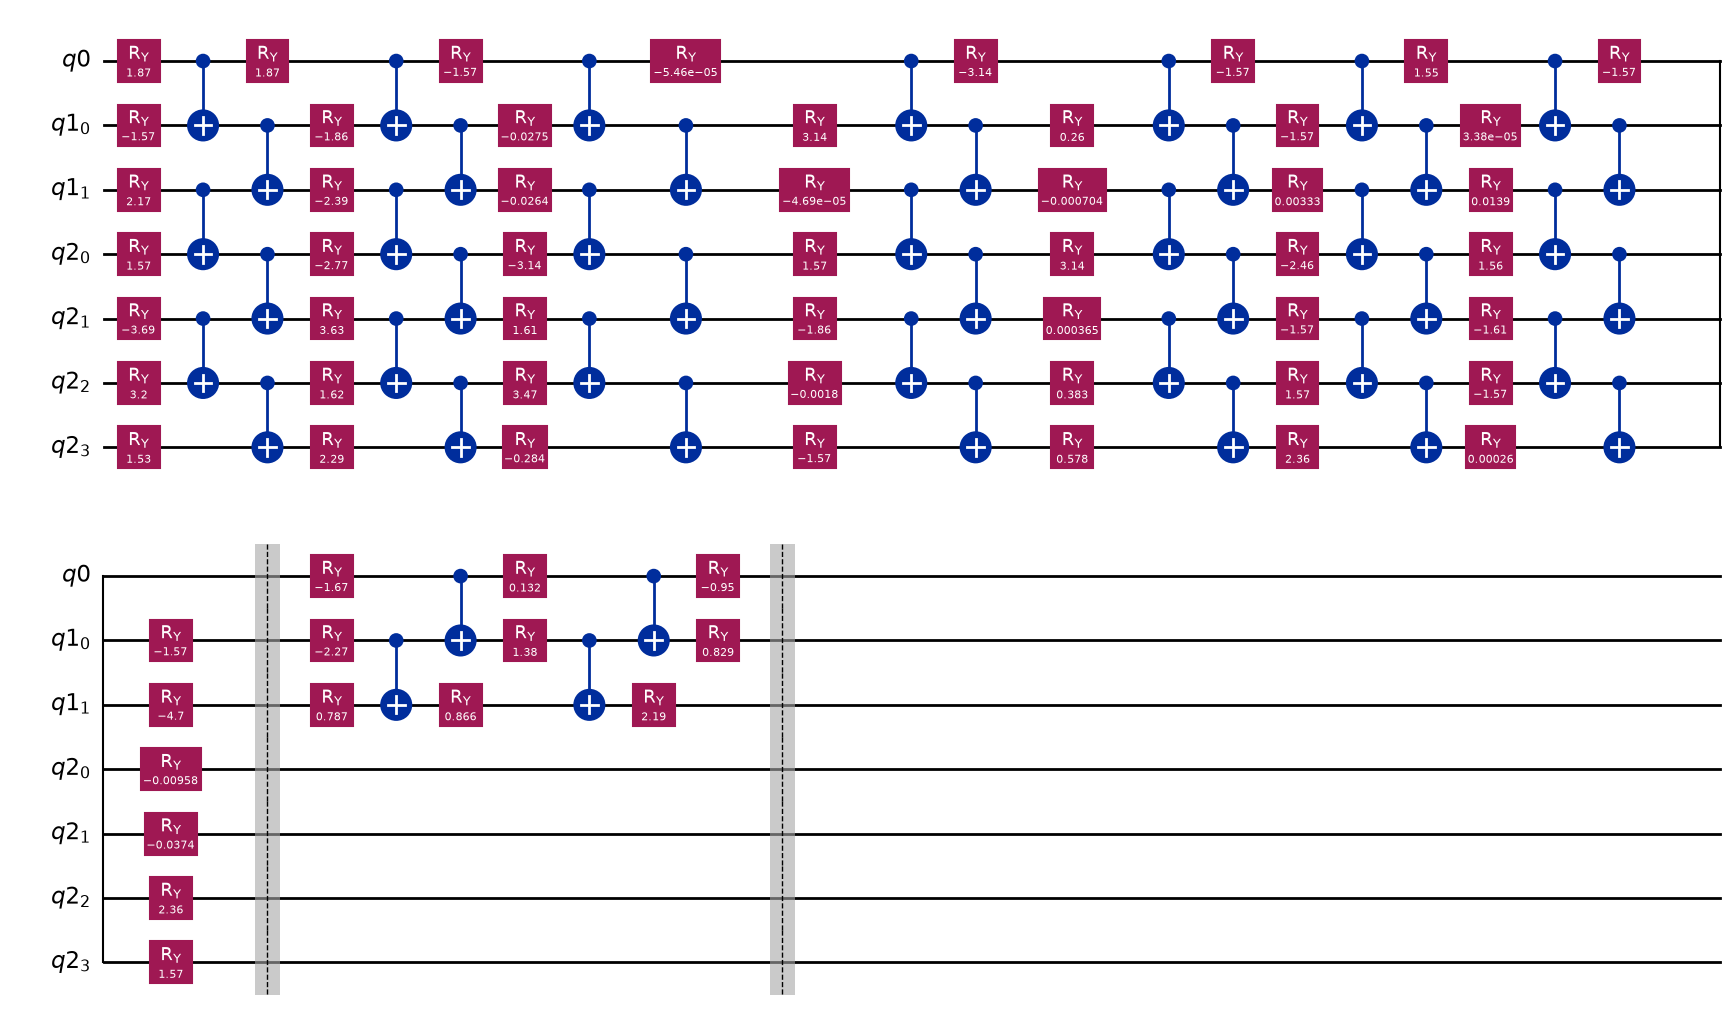

In [21]:
display(qc.draw("mpl"))

# <u>**Part 2: Use Grover Search for Image Matching**</u>

In [ ]:
try:
    A_saved = load_parameters(scheme="FRQI", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]

    print(f"Loaded saved dataset encoder. Fidelity = {A_saved_best_fidelity:.6f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset encoder. Train again.")

Loaded saved A. Fidelity = 0.982606


In [23]:
A_parameters

array([ 1.86652928e+00, -1.56646779e+00,  2.16732135e+00,  1.57277357e+00,
       -3.68690360e+00,  3.19805321e+00,  1.52534617e+00,  1.86572268e+00,
       -1.85941742e+00, -2.38772722e+00, -2.76782469e+00,  3.62968286e+00,
        1.61922444e+00,  2.29020731e+00, -1.56671694e+00, -2.75070859e-02,
       -2.63605883e-02, -3.14437765e+00,  1.61477574e+00,  3.47404352e+00,
       -2.83924339e-01, -5.45929352e-05,  3.14136828e+00, -4.69353480e-05,
        1.57371160e+00, -1.86224942e+00, -1.79538865e-03, -1.56584972e+00,
       -3.14160877e+00,  2.59583841e-01, -7.03850638e-04,  3.14170367e+00,
        3.65083973e-04,  3.83422360e-01,  5.78286473e-01, -1.57081502e+00,
       -1.57076166e+00,  3.32568666e-03, -2.45759386e+00, -1.57057978e+00,
        1.57088987e+00,  2.35624662e+00,  1.55347086e+00,  3.37506192e-05,
        1.38762538e-02,  1.56430731e+00, -1.60692081e+00, -1.57143432e+00,
        2.60248764e-04, -1.57111952e+00, -1.57116487e+00, -4.70320632e+00,
       -9.58371164e-03, -

In [ ]:
GS = GroverSearch()

## <u>**GS with FRQI scheme and MMD cost function**</u>

In [ ]:
# GS.run(dataset=dataset, query=query,
#     A_parameters=A_parameters_frqi_mmd, B_parameters=B_parameters_frqi_mmd,
#     depth_A=6, depth_B=3,
#     num_of_iter=5
# )

In [ ]:
query_index

In [ ]:
# GS.draw_circuit()

In [ ]:
# GS.analysis()

## <u>**GS with FRQI scheme and FIDELITY cost function**</u>

In [ ]:
GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters, B_parameters=B_parameters_frqi_fidelity,
    depth_A=pqc_depth_for_dataset_encoder, depth_B=pqc_depth_for_query_encoder,
    num_of_iter=5
)

In [ ]:
GS.draw_circuit()

In [ ]:
GS.analysis()